# Krok 1: Wczytanie zbioru danych Fashion-MNIST
Zbiór Fashion-MNIST zawiera 70 000 czarno-białych obrazków o rozmiarze 28x28 pikseli, przedstawiających 10 różnych kategorii ubrań i dodatków.

In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

# Wczytanie wbudowanego zbioru danych Fashion-MNIST
fashion_mnist = keras.datasets.fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Słownik z nazwami klas (etykiety od 0 do 9)
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Wyświetlenie wymiarów danych
print(f"Zbiór treningowy (obrazy): {X_train.shape}")
print(f"Zbiór treningowy (etykiety): {y_train.shape}")
print(f"Zbiór testowy (obrazy): {X_test.shape}")
print(f"Zbiór testowy (etykiety): {y_test.shape}")

Zbiór treningowy (obrazy): (60000, 28, 28)
Zbiór treningowy (etykiety): (60000,)
Zbiór testowy (obrazy): (10000, 28, 28)
Zbiór testowy (etykiety): (10000,)


### Wizualizacja przykładowego obrazka
Zobaczmy, jak komputer "widzi" jeden z tych obrazów.

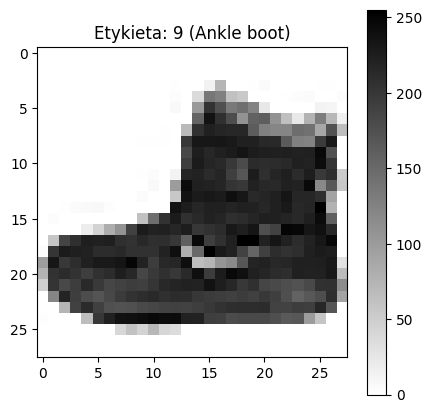

In [ ]:
# Wyświetlamy pierwszy obrazek ze zbioru treningowego
plt.figure(figsize=(5,5))
plt.imshow(X_train[0], cmap='binary')
plt.title(f"Etykieta: {y_train[0]} ({class_names[y_train[0]]})")
plt.colorbar()
plt.grid(False)
plt.show()

# Krok 2: Normalizacja danych
Przeskalujemy wartości pikseli z przedziału [0, 255] do przedziału [0.0, 1.0].

In [ ]:
# Normalizacja zbioru treningowego i testowego
X_train = X_train / 255.0
X_test = X_test / 255.0

# Sprawdźmy wartości pikseli po normalizacji
print(f"Minimalna wartość piksela: {X_train.min()}")
print(f"Maksymalna wartość piksela: {X_train.max()}")

Minimalna wartość piksela: 0.0
Maksymalna wartość piksela: 1.0


Po uruchomieniu tej komórki nasze dane będą gotowe do nakarmienia nimi sieci neuronowej! Daj znać, czy wszystko na tym etapie jest dla Ciebie jasne.

# Krok 3: Definiowanie architektury modelu
Tworzymy model sekwencyjny składający się z warstwy spłaszczającej, jednej warstwy ukrytej (gęstej) oraz warstwy wyjściowej.

In [ ]:
# Tworzymy model
model = keras.Sequential([
    # 1. Spłaszczenie obrazu 28x28 do wektora 784 elementów
    keras.layers.Flatten(input_shape=(28, 28)),

    # 2. Warstwa ukryta ze 128 neuronami i aktywacją ReLU
    keras.layers.Dense(128, activation='relu'),

    # 3. Warstwa wyjściowa z 10 neuronami (po jednym dla każdej klasy) i aktywacją Softmax
    keras.layers.Dense(10, activation='softmax')
])

# Podsumowanie struktury sieci
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Uruchom powyższą komórkę. Zwróć uwagę na tabelę podsumowującą model (szczególnie na kolumnę **Param #**, czyli liczbę wag i obciążeń, których nasza sieć będzie musiała się nauczyć).

Jak będziesz gotowy, daj znać! W kolejnym kroku wyjaśnię Ci, jak przygotować model do treningu za pomocą kompilacji.

# Krok 4: Kompilacja modelu
Konfigurujemy proces uczenia się przy użyciu optymalizatora Adam, odpowiedniej funkcji straty i metryki dokładności.

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Krok 5: Trening modelu
Trenujemy model przez 10 epok. Zapiszemy historię treningu do zmiennej `history`, aby później móc ją łatwo przeanalizować.

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.1 # 10% danych treningowych posłuży jako walidacja w trakcie nauki
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8244 - loss: 0.5049 - val_accuracy: 0.8545 - val_loss: 0.3986
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8651 - loss: 0.3771 - val_accuracy: 0.8707 - val_loss: 0.3695
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8770 - loss: 0.3391 - val_accuracy: 0.8757 - val_loss: 0.3412
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8853 - loss: 0.3136 - val_accuracy: 0.8720 - val_loss: 0.3469
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8907 - loss: 0.2969 - val_accuracy: 0.8820 - val_loss: 0.3235
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8955 - loss: 0.2821 - val_accuracy: 0.8848 - val_loss: 0.3204
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8993 - loss: 0.2676 - val_accuracy: 0.8823 - val_loss: 0.3394
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9044 - loss: 0.2570 

# Krok 6: Ocena modelu na zbiorze testowym
Sprawdzamy rzeczywistą skuteczność naszego modelu na danych, których nigdy wcześniej nie widział.

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nDokładność na zbiorze testowym: {test_acc:.4f}")

313/313 - 1s - 2ms/step - accuracy: 0.8825 - loss: 0.3458

Dokładność na zbiorze testowym: 0.8825


# Krok 7: Wizualizacja predykcji dla pojedynczego obrazka
Sprawdźmy, jak model radzi sobie z konkretnym przykładem. Wybierzemy pierwszy obrazek ze zbioru testowego i zobaczymy, jakie prawdopodobieństwa przypisał poszczególnym kategoriom.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


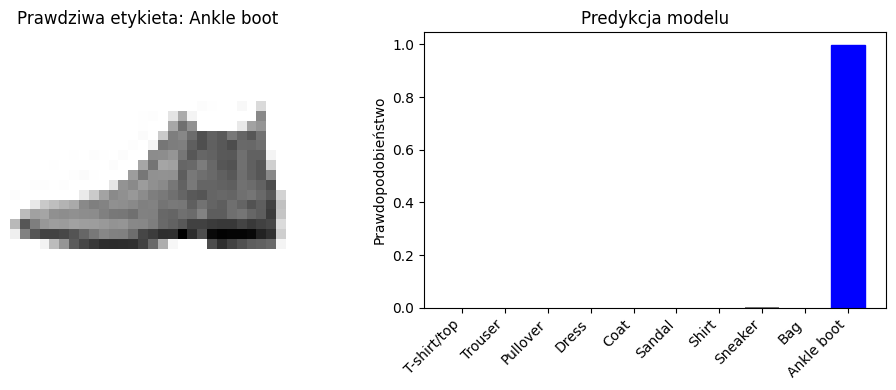

In [ ]:
# Generujemy prognozy dla wszystkich obrazów testowych
predictions = model.predict(X_test)

# Wybierzmy indeks obrazka, który chcemy zbadać (np. indeks 0)
img_index = 0

plt.figure(figsize=(10,4))

# 1. Rysunek obrazka
plt.subplot(1, 2, 1)
plt.imshow(X_test[img_index], cmap='binary')
plt.title(f"Prawdziwa etykieta: {class_names[y_test[img_index]]}")
plt.axis('off')

# 2. Wykres słupkowy prawdopodobieństwa
plt.subplot(1, 2, 2)
plt.bar(range(10), predictions[img_index], color="#777777")
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.ylabel('Prawdopodobieństwo')
plt.title('Predykcja modelu')

# Zaznaczmy na czerwono/niebiesko najwyższy słupek
predicted_label = np.argmax(predictions[img_index])
plt.gca().get_children()[predicted_label].set_color('blue' if predicted_label == y_test[img_index] else 'red')

plt.tight_layout()
plt.show()

# Krok 8: Wykresy dokładności i straty
Wizualizacja procesu uczenia w czasie (porównanie zbioru treningowego i walidacyjnego).

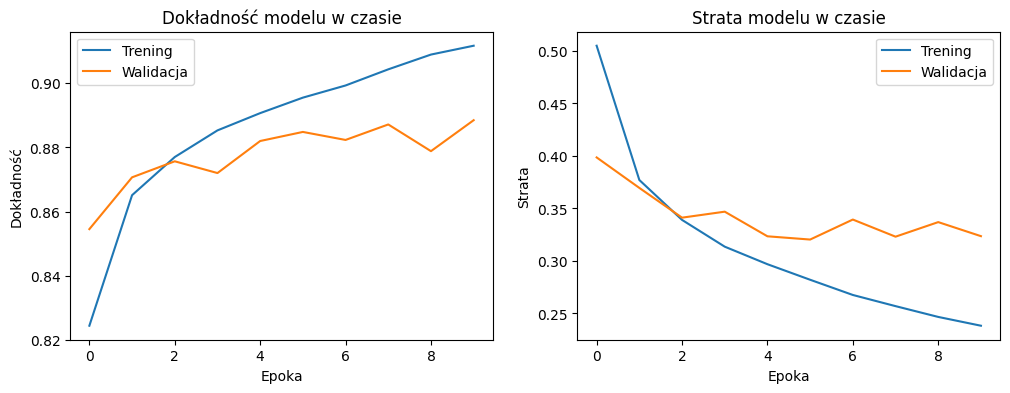

In [ ]:
plt.figure(figsize=(12, 4))

# Wykres dokładności (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Trening')
plt.plot(history.history['val_accuracy'], label='Walidacja')
plt.title('Dokładność modelu w czasie')
plt.xlabel('Epoka')
plt.ylabel('Dokładność')
plt.legend()

# Wykres straty (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Trening')
plt.plot(history.history['val_loss'], label='Walidacja')
plt.title('Strata modelu w czasie')
plt.xlabel('Epoka')
plt.ylabel('Strata')
plt.legend()

plt.show()

Uruchom tę komórkę. Zauważ, jak na wykresie straty (Loss) linia treningowa stale spada, ale linia walidacyjna w pewnym momencie zaczyna się stabilizować lub nawet lekko rosnąć. To jest właśnie moment, w którym sieć zaczyna uczyć się szczegółów obrazków treningowych na pamięć (overfitting) zamiast ogólnych cech ubrań.

Daj znać, czy te wykresy są dla Ciebie czytelne i czy masz pytania do któregoś z kroków, które dzisiaj zrobiliśmy!

# Krok 9: Dodanie warstwy Dropout w celu redukcji przeuczenia
Tworzymy nową wersję modelu, dodając warstwę `Dropout` z parametrem 0.2 (20% wyłączanych neuronów).

In [ ]:
# Definicja nowego modelu z warstwą Dropout
model_dropout = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.2),  # Losowo wyłączamy 20% neuronów w każdej iteracji
    keras.layers.Dense(10, activation='softmax')
])

# Kompilacja nowego modelu
model_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Trening nowego modelu
history_dropout = model_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8085 - loss: 0.5426 - val_accuracy: 0.8467 - val_loss: 0.4125
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8535 - loss: 0.4046 - val_accuracy: 0.8678 - val_loss: 0.3567
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8644 - loss: 0.3710 - val_accuracy: 0.8703 - val_loss: 0.3517
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8716 - loss: 0.3483 - val_accuracy: 0.8657 - val_loss: 0.3720
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8773 - loss: 0.3333 - val_accuracy: 0.8695 - val_loss: 0.3478
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8830 - loss: 0.3190 - val_accuracy: 0.8800 - val_loss: 0.3316
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8833 - loss: 0.3123 - val_accuracy: 0.8827 - val_loss: 0.3247
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8886 - loss: 0.3021 - 

### Ocena nowego modelu z Dropoutem
Sprawdźmy teraz, jak model radzi sobie na danych testowych i porównajmy go z poprzednim wynikiem.

In [ ]:
test_loss_dp, test_acc_dp = model_dropout.evaluate(X_test, y_test, verbose=2)
print(f"\nDokładność starego modelu (bez Dropoutu): {test_acc:.4f}")
print(f"Dokładność nowego modelu (z Dropoutem): {test_acc_dp:.4f}")

313/313 - 1s - 2ms/step - accuracy: 0.8818 - loss: 0.3346

Dokładność starego modelu (bez Dropoutu): 0.8825
Dokładność nowego modelu (z Dropoutem): 0.8818


# Krok 10: Wizualizacja zjawiska Underfittingu (Niedouczenia)
Aby lepiej zrozumieć to pojęcie, zasymulujmy i wyświetlmy przykładowy wykres dla modelu, który cierpi na niedouczenie.

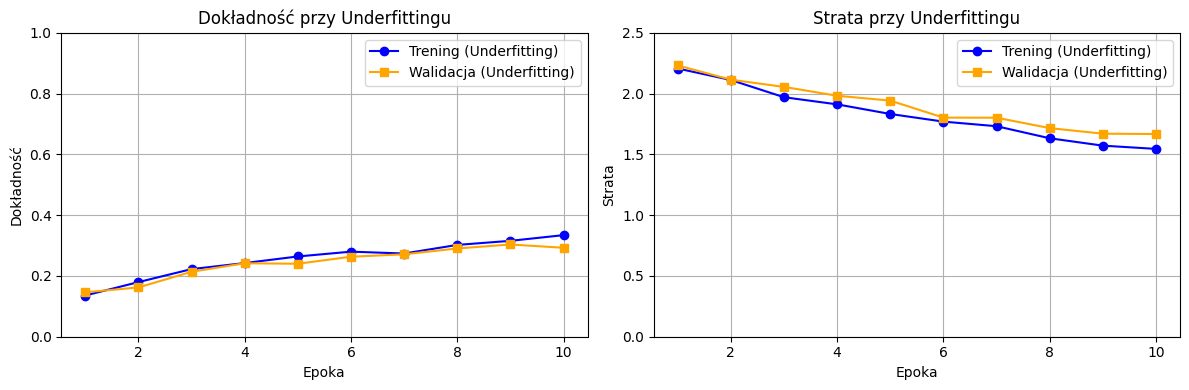

In [ ]:
# Generujemy sztuczne dane obrazujące typowy przebieg underfittingu
epoki = np.arange(1, 11)
# Model słabo się uczy, strata prawie nie spada i zostaje wysoko
train_loss_under = 2.3 / (1 + 0.05 * epoki) + np.random.normal(0, 0.02, 10)
val_loss_under = 2.3 / (1 + 0.04 * epoki) + np.random.normal(0, 0.02, 10)

# Dokładność rośnie bardzo wolno i zostaje na bardzo niskim poziomie (np. w okolicach 30-40%)
train_acc_under = 0.1 + 0.25 * (1 - np.exp(-0.2 * epoki)) + np.random.normal(0, 0.01, 10)
val_acc_under = 0.1 + 0.23 * (1 - np.exp(-0.2 * epoki)) + np.random.normal(0, 0.01, 10)

# Rysowanie wykresów
plt.figure(figsize=(12, 4))

# Wykres Dokładności (Underfitting)
plt.subplot(1, 2, 1)
plt.plot(epoki, train_acc_under, 'o-', label='Trening (Underfitting)', color='blue')
plt.plot(epoki, val_acc_under, 's-', label='Walidacja (Underfitting)', color='orange')
plt.title('Dokładność przy Underfittingu')
plt.xlabel('Epoka')
plt.ylabel('Dokładność')
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True)

# Wykres Straty (Underfitting)
plt.subplot(1, 2, 2)
plt.plot(epoki, train_loss_under, 'o-', label='Trening (Underfitting)', color='blue')
plt.plot(epoki, val_loss_under, 's-', label='Walidacja (Underfitting)', color='orange')
plt.title('Strata przy Underfittingu')
plt.xlabel('Epoka')
plt.ylabel('Strata')
plt.ylim(0, 2.5)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Krok 11: Tuning hiperparametrów - większa sieć i kontrola tempa uczenia (Learning Rate)
Aby poprawić wyniki i lepiej zrozumieć wpływ architektury, stworzymy teraz nieco większą sieć (256 neuronów) oraz jawnie zdefiniujemy **learning rate** (tempo uczenia się) dla optymalizatora Adam.

Zbyt wysoki learning rate może powodować niestabilność (model "skacze" i nie może znaleźć minimum), natomiast zbyt niski sprawi, że model będzie uczył się bardzo wolno (co może prowadzić do underfittingu przy małej liczbie epok).

In [ ]:
# 1. Definicja nowego modelu z większą liczbą neuronów
model_tuned = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dropout(0.3),  # Zwiększamy dropout do 30% przy większej liczbie neuronów
    keras.layers.Dense(10, activation='softmax')
])

# 2. Ustawienie własnego tempa uczenia (learning rate)
custom_optimizer = keras.optimizers.Adam(learning_rate=0.0005)

# 3. Kompilacja
model_tuned.compile(
    optimizer=custom_optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Trening
history_tuned = model_tuned.fit(
    X_train,
    y_train,
    epochs=12,  # Trenujemy nieco dłużej
    validation_split=0.1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8048 - loss: 0.5582 - val_accuracy: 0.8467 - val_loss: 0.4215
Epoch 2/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8535 - loss: 0.4112 - val_accuracy: 0.8708 - val_loss: 0.3599
Epoch 3/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8658 - loss: 0.3728 - val_accuracy: 0.8727 - val_loss: 0.3571
Epoch 4/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8742 - loss: 0.3490 - val_accuracy: 0.8703 - val_loss: 0.3457
Epoch 5/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8787 - loss: 0.3311 - val_accuracy: 0.8713 - val_loss: 0.3517
Epoch 6/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8828 - loss: 0.3180 - val_accuracy: 0.8822 - val_loss: 0.3273
Epoch 7/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8876 - loss: 0.3050 - val_accuracy: 0.8812 - val_loss: 0.3318
Epoch 8/12
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8889 - loss: 0.29

Zweryfikujmy teraz skuteczność tego dostrojonego modelu na zbiorze testowym i porównajmy go z poprzednimi modelami.

In [ ]:
test_loss_tuned, test_acc_tuned = model_tuned.evaluate(X_test, y_test, verbose=2)
print(f"\nDokładność bazowego modelu: {test_acc:.4f}")
print(f"Dokładność modelu z Dropout: {test_acc_dp:.4f}")
print(f"Dokładność dostrojonego modelu (256 neuronów, lr=0.0005): {test_acc_tuned:.4f}")

313/313 - 1s - 2ms/step - accuracy: 0.8811 - loss: 0.3272

Dokładność bazowego modelu: 0.8825
Dokładność modelu z Dropout: 0.8818
Dokładność dostrojonego modelu (256 neuronów, lr=0.0005): 0.8811


### Wizualizacja wyników dostrojonego modelu
Porównajmy proces uczenia się nowego modelu ze zoptymalizowanym tempem uczenia (learning rate) i większą liczbą neuronów.

In [ ]:
plt.figure(figsize=(12, 4))

# Wykres dokładności (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['accuracy'], label='Trening (Tuned)')
plt.plot(history_tuned.history['val_accuracy'], label='Walidacja (Tuned)')
plt.title('Dokładność dostrojonego modelu')
plt.xlabel('Epoka')
plt.ylabel('Dokładność')
plt.legend()
plt.grid(True)

# Wykres straty (Loss)
plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['loss'], label='Trening (Tuned)')
plt.plot(history_tuned.history['val_loss'], label='Walidacja (Tuned)')
plt.title('Strata dostrojonego modelu')
plt.xlabel('Epoka')
plt.ylabel('Strata')
plt.legend()
plt.grid(True)

plt.show()

### Wizualizacja wyników dostrojonego modelu (Tuned Model)

Zobaczmy, jak przebiegał proces uczenia się z mniejszym krokiem uczenia (`learning_rate=0.0005`) oraz większą warstwą ukrytą (256 neuronów).

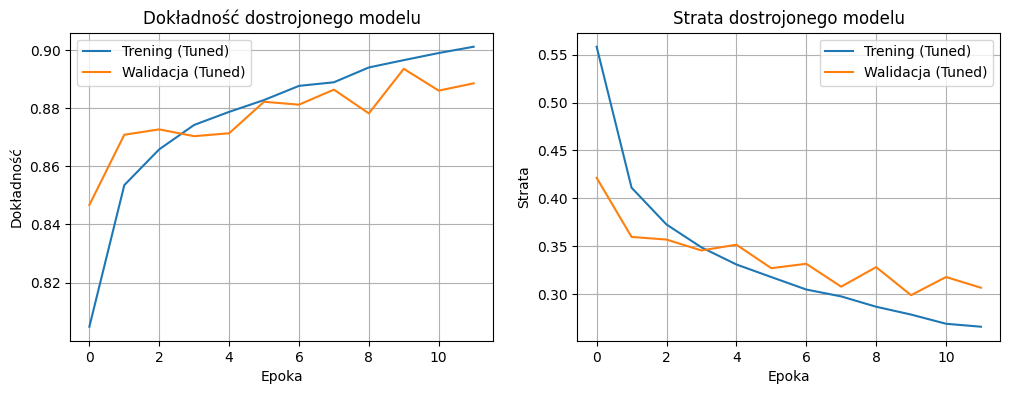

In [ ]:
plt.figure(figsize=(12, 4))

# Wykres dokładności (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['accuracy'], label='Trening (Tuned)')
plt.plot(history_tuned.history['val_accuracy'], label='Walidacja (Tuned)')
plt.title('Dokładność dostrojonego modelu')
plt.xlabel('Epoka')
plt.ylabel('Dokładność')
plt.legend()
plt.grid(True)

# Wykres straty (Loss)
plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['loss'], label='Trening (Tuned)')
plt.plot(history_tuned.history['val_loss'], label='Walidacja (Tuned)')
plt.title('Strata dostrojonego modelu')
plt.xlabel('Epoka')
plt.ylabel('Strata')
plt.legend()
plt.grid(True)

plt.show()

### Krok 12: Macierz Pomyłek (Confusion Matrix)
Stworzymy macierz pomyłek, aby dokładnie sprawdzić, które klasy ubrań są najczęściej ze sobą mylone przez nasz dostrojony model.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


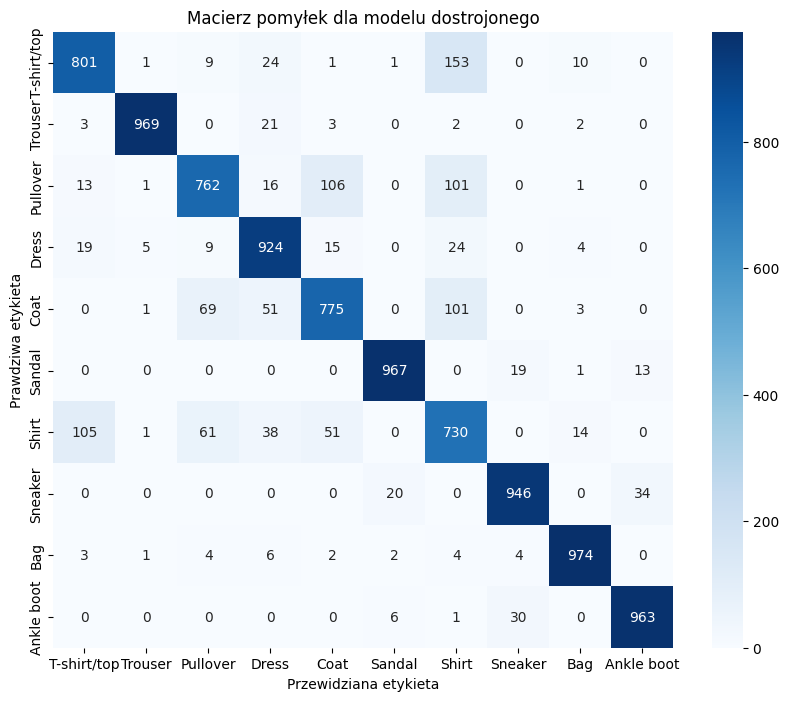

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 1. Uzyskanie przewidywanych klas (indeks o najwyższym prawdopodobieństwie)
y_pred = np.argmax(model_tuned.predict(X_test), axis=-1)

# 2. Obliczenie macierzy pomyłek
cm = confusion_matrix(y_test, y_pred)

# 3. Wizualizacja za pomocą seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Macierz pomyłek dla modelu dostrojonego')
plt.ylabel('Prawdziwa etykieta')
plt.xlabel('Przewidziana etykieta')
plt.show()

### Krok 13: Splotowe Sieci Neuronowe (CNN)
Przekształcimy wymiary naszych danych wejściowych, aby dodać wymiar kanału (wymagany przez warstwy splotowe), a następnie zbudujemy zaawansowany model CNN.

In [ ]:
# 1. Zmiana kształtu danych wejściowych (dodanie kanału koloru)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print(f"Nowy kształt danych treningowych: {X_train_cnn.shape}")

# 2. Definicja modelu CNN
model_cnn = keras.Sequential([
    # Pierwsza warstwa splotowa: 32 filtry o rozmiarze 3x3
    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    # Warstwa łącząca (Pooling): zmniejsza wymiary o połowę
    keras.layers.MaxPooling2D((2, 2)),

    # Druga warstwa splotowa: 64 filtry
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),

    # Spłaszczenie do wektora i klasyczna warstwa gęsta
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation='softmax')
])

# 3. Kompilacja modelu
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Podsumowanie architektury CNN
model_cnn.summary()

Nowy kształt danych treningowych: (60000, 28, 28, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Uruchommy teraz trening tego modelu na 10 epokach. Zwróć uwagę, jak wysokie wyniki dokładności osiągnie ta struktura!

In [ ]:
history_cnn = model_cnn.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 53s 30ms/step - accuracy: 0.7985 - loss: 0.5550 - val_accuracy: 0.8547 - val_loss: 0.3883
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 49s 29ms/step - accuracy: 0.8680 - loss: 0.3697 - val_accuracy: 0.8887 - val_loss: 0.2955
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.8835 - loss: 0.3192 - val_accuracy: 0.8962 - val_loss: 0.2748
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.8965 - loss: 0.2864 - val_accuracy: 0.9040 - val_loss: 0.2638
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 50s 29ms/step - accuracy: 0.9041 - loss: 0.2639 - val_accuracy: 0.9068 - val_loss: 0.2472
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 48s 29ms/step - accuracy: 0.9098 - loss: 0.2430 - val_accuracy: 0.9092 - val_loss: 0.2422
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9158 - loss: 0.2266 - val_accuracy: 0.9095 - val_loss: 0.2471
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9207 -

### Ocena modelu CNN na zbiorze testowym
Sprawdźmy, jak splotowa sieć neuronowa radzi sobie z obrazami testowymi, których nigdy wcześniej nie widziała.

In [ ]:
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test_cnn, y_test, verbose=2)
print(f"\nDokładność modelu gęstego (Tuned): {test_acc_tuned:.4f}")
print(f"Dokładność modelu splotowego (CNN): {test_acc_cnn:.4f}")

313/313 - 3s - 11ms/step - accuracy: 0.9109 - loss: 0.2586

Dokładność modelu gęstego (Tuned): 0.8811
Dokładność modelu splotowego (CNN): 0.9109


### Wizualizacja historii uczenia CNN
Narysujmy wykresy straty i dokładności dla modelu splotowego.

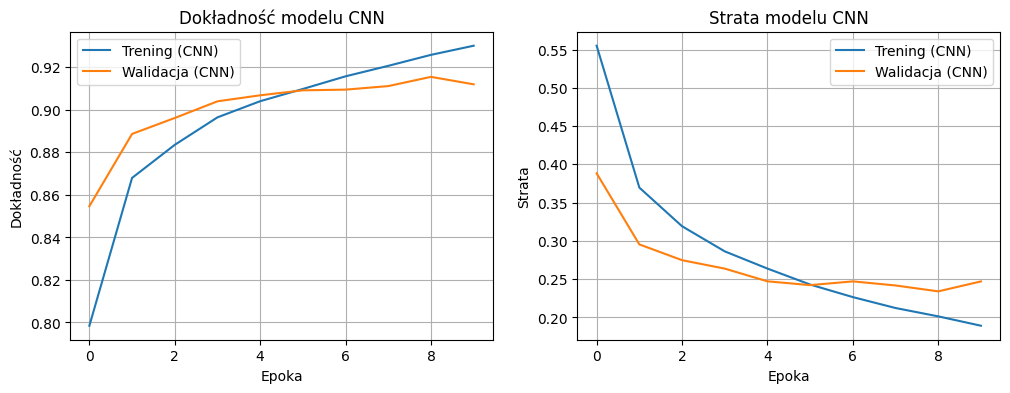

In [ ]:
plt.figure(figsize=(12, 4))

# Wykres dokładności (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Trening (CNN)')
plt.plot(history_cnn.history['val_accuracy'], label='Walidacja (CNN)')
plt.title('Dokładność modelu CNN')
plt.xlabel('Epoka')
plt.ylabel('Dokładność')
plt.legend()
plt.grid(True)

# Wykres straty (Loss)
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Trening (CNN)')
plt.plot(history_cnn.history['val_loss'], label='Walidacja (CNN)')
plt.title('Strata modelu CNN')
plt.xlabel('Epoka')
plt.ylabel('Strata')
plt.legend()
plt.grid(True)

plt.show()

### Krok 14: Macierz Pomyłek dla modelu CNN
Sprawdźmy, czy sieć splotowa lepiej odróżnia trudne kategorie, takie jak koszule, t-shirty czy płaszcze.

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


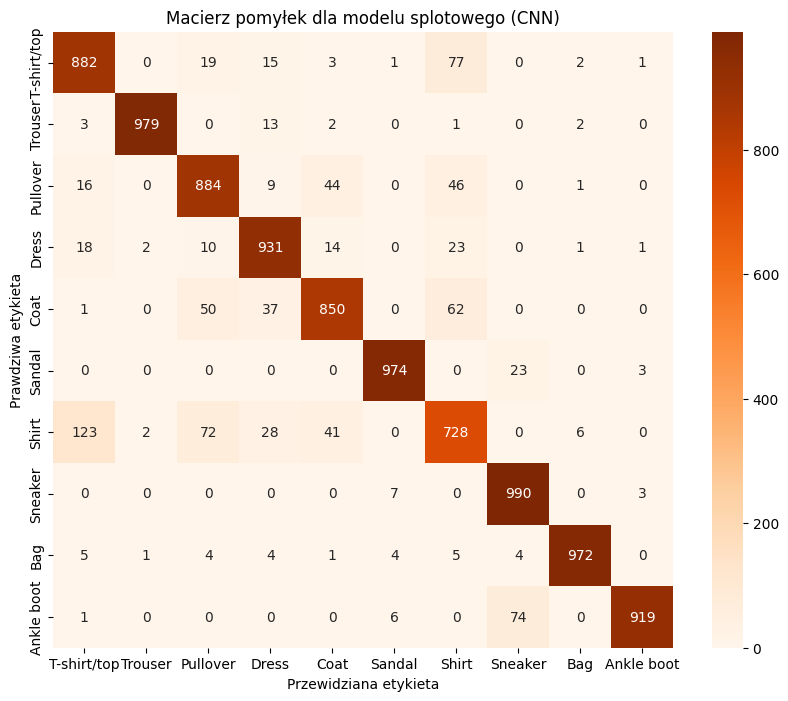

In [ ]:
# 1. Generujemy przewidywania modelu CNN na zbiorze testowym
y_pred_cnn = np.argmax(model_cnn.predict(X_test_cnn), axis=-1)

# 2. Obliczamy macierz pomyłek dla CNN
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

# 3. Wizualizacja
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Macierz pomyłek dla modelu splotowego (CNN)')
plt.ylabel('Prawdziwa etykieta')
plt.xlabel('Przewidziana etykieta')
plt.show()

Uruchom tę komórkę. Zauważ, że w przypadku underfittingu obie linie (trening i walidacja) leżą bardzo blisko siebie, ale wynik jest fatalny – błąd (strata) jest gigantyczny, a skuteczność niska. Model po prostu się nie nauczył.

Uruchom powyższe komórki! Zwróć uwagę, czy różnica między dokładnością treningową a walidacyjną zmniejszyła się w trakcie epok.

Uruchom te komórki! Zobaczysz, czy model poprawnie odgadł pierwszy artykuł ze zbioru testowego oraz jak bardzo był pewny swojej decyzji.

Uruchom powyższe komórki i daj znać, jak poszedł trening! Przeanalizujemy uzyskane wyniki.